In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from statsmodels.stats.outliers_influence import variance_inflation_factor

import warnings
warnings.filterwarnings('ignore')



In [2]:
df = pd.read_csv("CAR DETAILS FROM CAR DEKHO.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (4340, 8)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [3]:
print("Dataset Information:")
df.info()

print("\nSummary Statistics:")
display(df.describe())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB

Summary Statistics:


,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000



Column Names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']


In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nInvalid Values:")
print("Invalid Year:", (df["year"] <= 0).sum())
print("Invalid KM Driven:", (df["km_driven"] < 0).sum())
print("Invalid Selling Price:", (df["selling_price"] <= 0).sum())

df = df.drop_duplicates()

print("\nDataset Shape After Removing Duplicates:", df.shape)

Missing Values:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Duplicate Records: 763

Invalid Values:
Invalid Year: 0
Invalid KM Driven: 0
Invalid Selling Price: 0

Dataset Shape After Removing Duplicates: (3577, 8)


In [5]:
df = df.dropna(subset=["year", "km_driven", "selling_price"])

df = df[
    (df["year"] > 0) &
    (df["km_driven"] >= 0) &
    (df["selling_price"] > 0)
].copy()

print("Dataset Shape After Cleaning:", df.shape)
print("\nMissing Values After Cleaning:")
print(df[["year", "km_driven", "selling_price"]].isnull().sum())

Dataset Shape After Cleaning: (3577, 8)

Missing Values After Cleaning:
year             0
km_driven        0
selling_price    0
dtype: int64


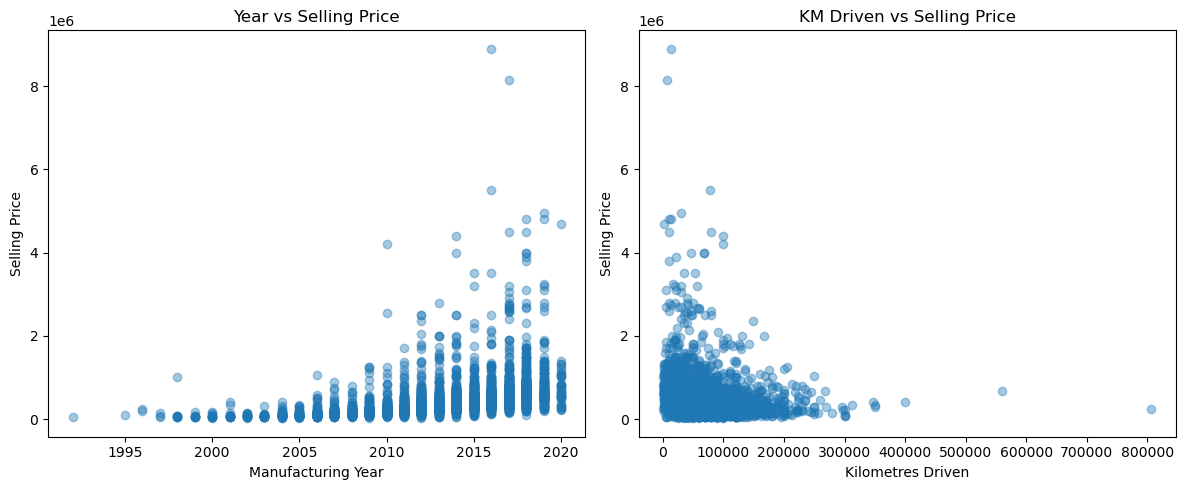

In [6]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(df["year"], df["selling_price"], alpha=0.4)
plt.title("Year vs Selling Price")
plt.xlabel("Manufacturing Year")
plt.ylabel("Selling Price")

plt.subplot(1, 2, 2)
plt.scatter(df["km_driven"], df["selling_price"], alpha=0.4)
plt.title("KM Driven vs Selling Price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Selling Price")

plt.tight_layout()
plt.show()

In [7]:
correlation = df[["year", "km_driven", "selling_price"]].corr()

print("Correlation Matrix:")
display(correlation)

Correlation Matrix:


,year,km_driven,selling_price
year,1.00000,-0.417490,0.424260
km_driven,-0.41749,1.000000,-0.187359
selling_price,0.42426,-0.187359,1.000000


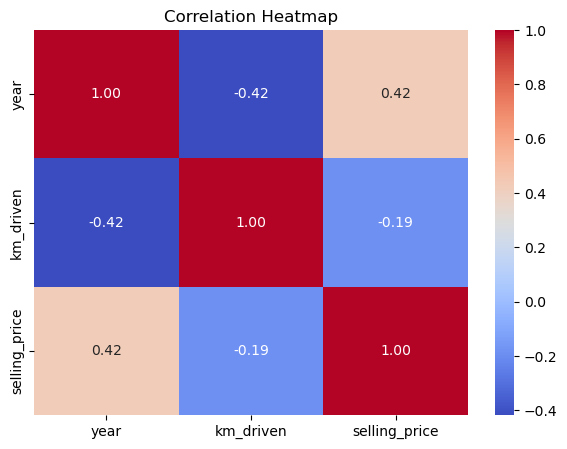

In [8]:
plt.figure(figsize=(7, 5))

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

Year has a positive correlation of approximately 0.41 with selling price.



KM driven has a negative correlation of approximately -0.19 with selling price.



Year and KM driven have a negative correlation of approximately -0.42.



The selected features show different relationships with selling price.



Correlation does not prove causation.

In [9]:
sample = df[["year", "km_driven", "selling_price"]].head(5)

display(sample)

,year,km_driven,selling_price
0,2007,70000,60000
1,2007,50000,135000
2,2012,100000,600000
3,2017,46000,250000
4,2014,141000,450000


In [10]:
X_manual = np.column_stack((
    np.ones(len(sample)),
    sample[["year", "km_driven"]].values
))

y_manual = sample["selling_price"].values

print("Design Matrix X:")
print(X_manual)

print("\nTarget Vector y:")
print(y_manual)

Design Matrix X:
[[1.000e+00 2.007e+03 7.000e+04]
 [1.000e+00 2.007e+03 5.000e+04]
 [1.000e+00 2.012e+03 1.000e+05]
 [1.000e+00 2.017e+03 4.600e+04]
 [1.000e+00 2.014e+03 1.410e+05]]

Target Vector y:
[ 60000 135000 600000 250000 450000]


A design matrix is created with a column of ones (for the intercept) and two input features. The target vector contains the actual selling prices.

In [11]:
XT = X_manual.T

XTX = XT @ X_manual
XTy = XT @ y_manual

print("Transpose of X:")
print(XT)

print("\nX Transpose multiplied by X:")
print(XTX)

print("\nX Transpose multiplied by y:")
print(XTy)

Transpose of X:
[[1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00]
 [2.007e+03 2.007e+03 2.012e+03 2.017e+03 2.014e+03]
 [7.000e+04 5.000e+04 1.000e+05 4.600e+04 1.410e+05]]

X Transpose multiplied by X:
[[5.0000000e+00 1.0057000e+04 4.0700000e+05]
 [1.0057000e+04 2.0228727e+07 8.1879600e+08]
 [4.0700000e+05 8.1879600e+08 3.9397000e+10]]

X Transpose multiplied by y:
[1.495000e+06 3.009115e+09 1.459000e+11]


The transpose of the design matrix is multiplied by the original matrix to calculate XᵀX. Similarly, Xᵀ is multiplied by the target vector to calculate Xᵀy. These values are used to find the regression coefficients.

In [12]:
coefficients = np.linalg.solve(XTX, XTy)

b0, b1, b2 = coefficients

print("Intercept (b0):", b0)
print("Coefficient b1 (Year):", b1)
print("Coefficient b2 (KM Driven):", b2)

Intercept (b0): -40272446.37394911
Coefficient b1 (Year): 20034.6451490861
Coefficient b2 (KM Driven): 3.363158735593679


The coefficients b0, b1 and b2 represent the intercept and the effect of the two input features on selling price.

In [13]:
print("Multiple Linear Regression Equation:")
print(f"Selling Price = {b0:.2f} + ({b1:.2f} × Year) + ({b2:.2f} × KM Driven)")

Multiple Linear Regression Equation:
Selling Price = -40272446.37 + (20034.65 × Year) + (3.36 × KM Driven)


The calculated coefficients are used to form the Multiple Linear Regression equation. This equation estimates the selling price using manufacturing year and kilometres driven.

In [14]:
predicted_value = b0 + b1 * sample.iloc[0]["year"] + b2 * sample.iloc[0]["km_driven"]

actual_value = sample.iloc[0]["selling_price"]

residual = actual_value - predicted_value

print("Actual Selling Price:", actual_value)
print("Predicted Selling Price:", predicted_value)
print("Residual:", residual)

Actual Selling Price: 60000
Predicted Selling Price: 172507.55175824868
Residual: -112507.55175824868


In [15]:
X = df[["year", "km_driven"]]
y = df["selling_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 2861
Testing Records: 716


In [16]:
train_corr = X_train.corrwith(y_train).abs()
best_feature = train_corr.idxmax()

X_single_train = X_train[[best_feature]]
X_single_test = X_test[[best_feature]]

single_model = LinearRegression()
single_model.fit(X_single_train, y_train)

single_pred = single_model.predict(X_single_test)

print("Selected Feature:", best_feature)
print("Intercept:", single_model.intercept_)
print("Coefficient:", single_model.coef_[0])
print("Test R2 Score:", r2_score(y_test, single_pred))

Selected Feature: year
Intercept: -100150538.91039623
Coefficient: 49987.230456966136
Test R2 Score: 0.1688624163365181


The dataset is divided into training and testing sets in an 80:20 ratio. The training data is used to build the model, while the testing data is used to evaluate its performance on unseen records.

A single-feature Linear Regression model is created using the feature most strongly correlated with the target variable. This model acts as a baseline for comparison with the Multiple Linear Regression model.

In [17]:
multi_model = LinearRegression()

multi_model.fit(X_train, y_train)

multi_pred = multi_model.predict(X_test)

print("Multiple Linear Regression Model")
print("Intercept:", multi_model.intercept_)

for feature, coefficient in zip(X.columns, multi_model.coef_):
    print(feature, ":", coefficient)

print("Test R2 Score:", r2_score(y_test, multi_pred))

Multiple Linear Regression Model
Intercept: -100034847.64105168
year : 49930.176111191104
km_driven : -0.012081885250368634
Test R2 Score: 0.16894770560727468


A Multiple Linear Regression model is trained using both input features, year and km_driven. The model learns the relationship between these features and the selling price using the training data.

In [18]:
manual_model = LinearRegression()

manual_model.fit(sample[["year", "km_driven"]], y_manual)

print("Manual Calculation Coefficients:")
print("Intercept:", b0)
print("Year:", b1)
print("KM Driven:", b2)

print("\nLibrary Model Coefficients:")
print("Intercept:", manual_model.intercept_)
print("Year:", manual_model.coef_[0])
print("KM Driven:", manual_model.coef_[1])

Manual Calculation Coefficients:
Intercept: -40272446.37394911
Year: 20034.6451490861
KM Driven: 3.363158735593679

Library Model Coefficients:
Intercept: -40272446.37369745
Year: 20034.64514896086
KM Driven: 3.363158735596807


The same five observations and two input features used in manual calculations are fitted using Scikit-learn Linear Regression. The coefficients are compared with the manually calculated coefficients to verify the results.

In [19]:
b0_full = multi_model.intercept_
b1_full, b2_full = multi_model.coef_

print("Multiple Linear Regression Equation:")

print(
    f"Selling Price = {b0_full:.2f} "
    f"+ ({b1_full:.2f} × Year) "
    f"+ ({b2_full:.2f} × KM Driven)"
)

Multiple Linear Regression Equation:
Selling Price = -100034847.64 + (49930.18 × Year) + (-0.01 × KM Driven)


The regression coefficients explain how each input feature affects the predicted selling price while keeping the other feature constant.
- Intercept: It represents the predicted selling price when both input features are zero. This may not be meaningful in the real-world car market.
- Year coefficient: It represents the change in predicted selling price for a one-year increase in manufacturing year, keeping kilometres driven constant.
- KM Driven coefficient: It represents the change in predicted selling price for one additional kilometre driven, keeping manufacturing year constant.

In [20]:
print("INTERPRETATION OF COEFFICIENTS")

print(f"\nIntercept: Rs. {b0_full:.2f}")

print(f"\nYear Coefficient: {b1_full:.2f}")
print("Change in predicted price for one additional manufacturing year.")

print(f"\nKM Driven Coefficient: {b2_full:.2f}")
print("Change in predicted price for one additional kilometre driven.")

INTERPRETATION OF COEFFICIENTS

Intercept: Rs. -100034847.64

Year Coefficient: 49930.18
Change in predicted price for one additional manufacturing year.

KM Driven Coefficient: -0.01
Change in predicted price for one additional kilometre driven.


In [21]:
standardized_coefficients = (
    multi_model.coef_ * X_train.std() / y_train.std()
)

standardized_results = pd.DataFrame({
    "Feature": X.columns,
    "Standardised Coefficient": standardized_coefficients
})

display(standardized_results)

,Feature,Standardised Coefficient
year,year,0.427900
km_driven,km_driven,-0.001183


Standardised coefficients help compare the relative influence of different features. Since year and kilometres driven have different units, standardisation makes their coefficients easier to compare. These values show association, not causation.

In [22]:
prediction_comparison = pd.DataFrame({
    "Actual Selling Price": y_test,
    "Predicted Selling Price": multi_pred
})

display(prediction_comparison.head(10))

,Actual Selling Price,Predicted Selling Price
1045,270000,724006.113627
3194,525000,673846.381696
1530,990000,622623.443863
553,3800000,724126.932479
1612,229999,174170.082141
2652,325000,323356.516212
152,210000,224296.323086
3985,500000,623964.533126
1059,790000,724011.296756
3788,360000,573490.672178


In [23]:
def calculate_metrics(actual, predicted, number_of_features):
    n = len(actual)

    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)

    adjusted_r2 = 1 - (
        (1 - r2) * (n - 1) / (n - number_of_features - 1)
    )

    return [mae, mse, rmse, r2, adjusted_r2]


single_metrics = calculate_metrics(y_test, single_pred, 1)
multiple_metrics = calculate_metrics(y_test, multi_pred, 2)

comparison_table = pd.DataFrame({
    "Evaluation Metric": ["MAE", "MSE", "RMSE", "R2 Score", "Adjusted R2"],
    "Single Linear Regression": single_metrics,
    "Multiple Linear Regression": multiple_metrics
})

display(comparison_table)

,Evaluation Metric,Single Linear Regression,Multiple Linear Regression
0,MAE,2.366269e+05,2.366065e+05
1,MSE,2.677371e+11,2.677097e+11
2,RMSE,5.174332e+05,5.174067e+05
3,R2 Score,1.688624e-01,1.689477e-01
4,Adjusted R2,1.676984e-01,1.666166e-01


Evaluation metrics help measure the performance of a regression model. We compare the single-feature model and multiple-feature model using MAE, MSE, RMSE, R² and Adjusted R² on the same testing dataset.

In [24]:
residuals = y_test - multi_pred

residual_table = pd.DataFrame({
    "Actual Selling Price": y_test,
    "Predicted Selling Price": multi_pred,
    "Residual": residuals
})

display(residual_table.head(10))

,Actual Selling Price,Predicted Selling Price,Residual
1045,270000,724006.113627,-4.540061e+05
3194,525000,673846.381696,-1.488464e+05
1530,990000,622623.443863,3.673766e+05
553,3800000,724126.932479,3.075873e+06
1612,229999,174170.082141,5.582892e+04
2652,325000,323356.516212,1.643484e+03
152,210000,224296.323086,-1.429632e+04
3985,500000,623964.533126,-1.239645e+05
1059,790000,724011.296756,6.598870e+04
3788,360000,573490.672178,-2.134907e+05


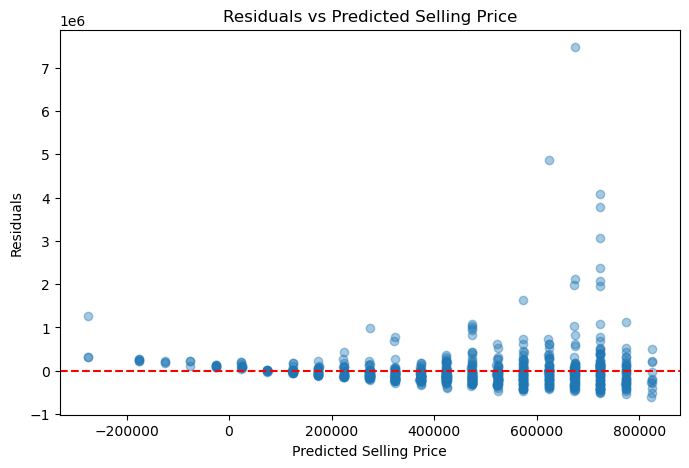

In [25]:
plt.figure(figsize=(8, 5))

plt.scatter(multi_pred, residuals, alpha=0.4)
plt.axhline(y=0, color="red", linestyle="--")

plt.title("Residuals vs Predicted Selling Price")
plt.xlabel("Predicted Selling Price")
plt.ylabel("Residuals")

plt.show()

This plot helps check whether prediction errors are randomly distributed. A random pattern around zero is generally desirable. A clear pattern may indicate that the linear model is not capturing the relationship properly.

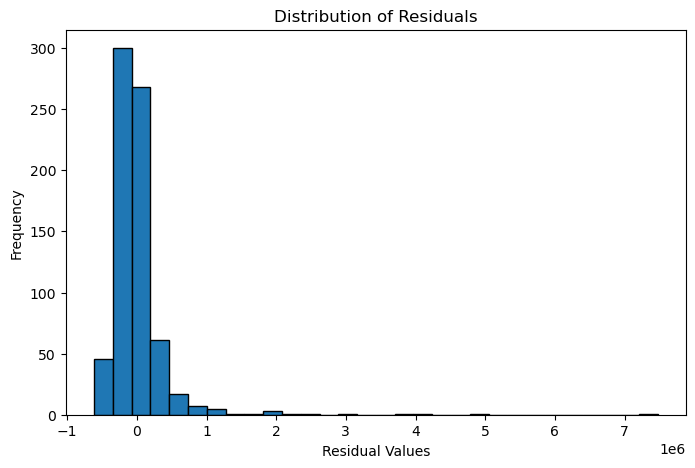

In [26]:
plt.figure(figsize=(8, 5))

plt.hist(residuals, bins=30, edgecolor="black")

plt.title("Distribution of Residuals")
plt.xlabel("Residual Values")
plt.ylabel("Frequency")

plt.show()

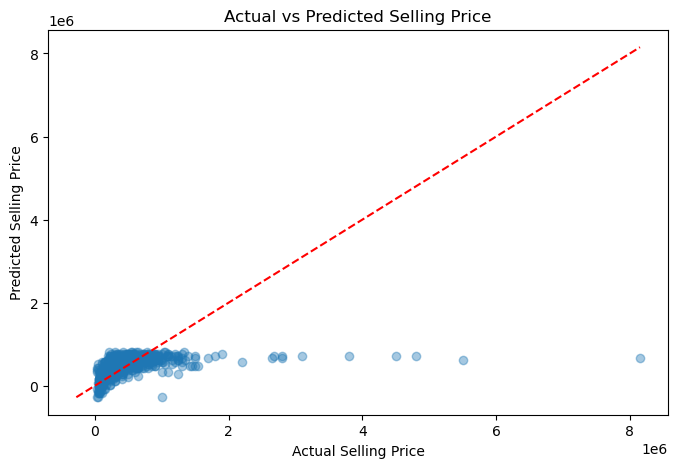

In [27]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, multi_pred, alpha=0.4)

minimum = min(y_test.min(), multi_pred.min())
maximum = max(y_test.max(), multi_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="red",
    linestyle="--"
)

plt.title("Actual vs Predicted Selling Price")
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")

plt.show()

In [28]:
from statsmodels.tools import add_constant

X_vif = add_constant(X_train)

vif_data = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

display(vif_data)


,Feature,VIF
0,const,273820.890270
1,year,1.205839
2,km_driven,1.205839


Multicollinearity occurs when two or more input features are highly related to each other. Variance Inflation Factor (VIF) helps identify this issue. A high VIF indicates that a feature may be strongly related to other input features.

In [29]:

print("REGRESSION ASSUMPTION CHECK")

print("\n1. Linearity:")
print("Check the scatter plots and residual plot for a linear relationship.")

print("\n2. Independence of Errors:")
print("Errors should be independent. This cannot be fully confirmed using these plots.")

print("\n3. Constant Variance:")
print("Check whether residuals have a roughly equal spread around zero.")

print("\n4. Normality of Errors:")
print("Check whether the residual histogram is approximately bell-shaped.")

print("\n5. Multicollinearity:")
for feature, value in zip(vif_data["Feature"], vif_data["VIF"]):
    if feature.lower() == "const":
        continue
    if value < 5:
        print(feature, "- Low multicollinearity (VIF:", round(value, 2), ")")
    elif value < 10:
        print(feature, "- Moderate multicollinearity (VIF:", round(value, 2), ")")
    else:
        print(feature, "- High multicollinearity (VIF:", round(value, 2), ")")


REGRESSION ASSUMPTION CHECK

1. Linearity:
Check the scatter plots and residual plot for a linear relationship.

2. Independence of Errors:
Errors should be independent. This cannot be fully confirmed using these plots.

3. Constant Variance:
Check whether residuals have a roughly equal spread around zero.

4. Normality of Errors:
Check whether the residual histogram is approximately bell-shaped.

5. Multicollinearity:
year - Low multicollinearity (VIF: 1.21 )
km_driven - Low multicollinearity (VIF: 1.21 )


In [30]:
new_car = pd.DataFrame({
    "year": [X_train["year"].median()],
    "km_driven": [X_train["km_driven"].median()]
})

new_prediction = multi_model.predict(new_car)

print("New Car Details:")
display(new_car)

print("Predicted Selling Price: Rs.", round(new_prediction[0], 2))

New Car Details:


,year,km_driven
0,2014.0,61585.0


Predicted Selling Price: Rs. 523782.98



### Prediction for a New Car

A new car record is created using the median values of year and kilometres driven from the training dataset. The trained Multiple Linear Regression model predicts the estimated selling price for this car.


In [31]:
print("MODEL PERFORMANCE SUMMARY")

print("\nSingle Linear Regression:")
print("R2 Score:", round(single_metrics[3], 4))
print("RMSE:", round(single_metrics[2], 2))

print("\nMultiple Linear Regression:")
print("R2 Score:", round(multiple_metrics[3], 4))
print("RMSE:", round(multiple_metrics[2], 2))

if multiple_metrics[3] > single_metrics[3]:
    print("\nThe multiple-feature model has a higher R2 score.")
else:
    print("\nThe single-feature model has an equal or higher R2 score.")

MODEL PERFORMANCE SUMMARY

Single Linear Regression:
R2 Score: 0.1689
RMSE: 517433.22

Multiple Linear Regression:
R2 Score: 0.1689
RMSE: 517406.67

The multiple-feature model has a higher R2 score.


In [32]:
decision_log = [
    "Selected the CarDekho dataset for used-car price prediction.",
    "Selected year and km_driven as numerical input features.",
    "Selected selling_price as the continuous target variable.",
    "Removed duplicate and invalid records and handled missing values.",
    "Used scatter plots and a correlation heatmap to explore relationships.",
    "Used the normal equation to calculate coefficients manually.",
    "Used an 80:20 training and testing split.",
    "Compared single-feature and multiple-feature regression models.",
    "Evaluated the models using MAE, MSE, RMSE, R2 and Adjusted R2.",
    "Used residual plots and VIF to examine model assumptions."
]

for decision in decision_log:
    print("-", decision)

- Selected the CarDekho dataset for used-car price prediction.
- Selected year and km_driven as numerical input features.
- Selected selling_price as the continuous target variable.
- Removed duplicate and invalid records and handled missing values.
- Used scatter plots and a correlation heatmap to explore relationships.
- Used the normal equation to calculate coefficients manually.
- Used an 80:20 training and testing split.
- Compared single-feature and multiple-feature regression models.
- Evaluated the models using MAE, MSE, RMSE, R2 and Adjusted R2.
- Used residual plots and VIF to examine model assumptions.


In this activity, Multiple Linear Regression was applied to the CarDekho dataset to predict the selling price of used cars. Manufacturing year and kilometres driven were selected as input features, while selling price was selected as the target variable.

The regression equation was calculated manually using the normal equation and verified using the Scikit-learn library. Single Linear Regression and Multiple Linear Regression were compared using an 80:20 training and testing split.

The models were evaluated using MAE, MSE, RMSE, R² and Adjusted R². Residual plots and VIF were also used to examine prediction errors and multicollinearity.

The model can help estimate used-car prices based on the selected features. However, selling price can also depend on other factors such as brand, fuel type, transmission, car condition and ownership history. Therefore, predictions may not always match actual market prices.